# FDA Assignment 1
**Course:** Foundations / Financial Data Analytics (FDA)  
**Assignment:** Chapter 1 — Sampling Techniques, Data Preprocessing & Machine Learning for Fraud Detection  
**Dataset:** `creditcard.csv` (Credit Card Transactions Dataset)  
**Objective:** Perform end-to-end data analysis including dataset inspection, sampling methods (partition, random, stratified, cluster), data selection (missing values, identical values, correlation, chi-square), class imbalance mitigation, machine learning model building, and comprehensive result analysis.

### Environment Setup: Package Installation
Verify package requirements including `imbalanced-learn` for handling skewed target classes.

In [1]:
# Install imbalanced-learn if required
# !pip install imbalanced-learn
import sys
print(f"Python interpreter: {sys.executable}")
print("Runtime environment verified successfully.")

Python interpreter: C:\Python312\python.exe
Runtime environment verified successfully.


### Library Imports
Import required scientific, statistical, visualization, preprocessing, resampling, and machine learning libraries as specified in the assignment template.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from collections import Counter
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE, ADASYN
from sklearn.feature_selection import chi2, SelectKBest
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score
)
import warnings
warnings.filterwarnings('ignore')

# Visual style configurations
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10
print("All libraries imported successfully!")

All libraries imported successfully!


### Dataset Loading
Load the provided `creditcard.csv` dataset and inspect the first records.

In [3]:
# Load the uploaded dataset
df = pd.read_csv("creditcard.csv")
print("Dataset loaded successfully.")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

Dataset loaded successfully.
Shape: 284,807 rows × 31 columns


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Column Inspection & Exploratory Overview
Examine column names, data types, missing values, duplicate records, and target class distribution.

In [4]:
# Inspect columns as in assignment template: print(list(df.columns))
print("Column Names:")
print(list(df.columns))

print("\n" + "="*50)
print("DATASET EXPLORATORY OVERVIEW")
print("="*50)
print(f"• Total Rows: {df.shape[0]:,}")
print(f"• Total Columns: {df.shape[1]}")
print(f"• Total Missing Values (NaN): {df.isnull().sum().sum()}")
print(f"• Total Duplicate Rows: {df.duplicated().sum():,}")

# Breakdown by data types
print(f"\nData Types Breakdown:\n{df.dtypes.value_counts()}")

# Class distribution
print("\nTarget Class Distribution (0 = Legitimate, 1 = Fraud):")
class_counts = df['Class'].value_counts()
class_pct = df['Class'].value_counts(normalize=True) * 100
summary_class = pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_pct.round(4)})
print(summary_class)

Column Names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

DATASET EXPLORATORY OVERVIEW
• Total Rows: 284,807
• Total Columns: 31
• Total Missing Values (NaN): 0


• Total Duplicate Rows: 1,081

Data Types Breakdown:
float64    30
int64       1
Name: count, dtype: int64

Target Class Distribution (0 = Legitimate, 1 = Fraud):
        Count  Percentage (%)
Class                        
0      284315         99.8273
1         492          0.1727


### Interpretation
The dataset contains **284,807 transactions** and **31 columns**. Features `V1` through `V28` are principal components obtained via PCA transformation, while `Time` (elapsed seconds from first transaction) and `Amount` (transaction sum) are unscaled numeric features. The binary target `Class` exhibits severe class imbalance: **284,315 legitimate transactions (99.827%)** versus only **492 fraudulent transactions (0.173%)**, requiring specialized sampling and class-imbalance mitigation techniques.

# Partition
### Task / Question
Perform a 70% random partition of the dataset.

### Solution
Extract a 70% fraction using `df.sample(frac=0.70, random_state=42)` and verify the partition length.

In [5]:
split_fraction = 0.70
partition = df.sample(frac=split_fraction, random_state=42)

print(f"Original Dataset Size: {len(df):,} records")
print(f"Partition Fraction: {split_fraction * 100:.0f}%")
print(f"Partition Length: {len(partition):,} records")

Original Dataset Size: 284,807 records
Partition Fraction: 70%
Partition Length: 199,365 records


### Interpretation
A 70% partition extracts **199,365 records** randomly without replacement. This random subset maintains the overall distribution of the dataset and provides a reliable partition for exploratory data analysis or holdout validation.

# Random
### Task / Question
Generate a simple random sample of 100 records and display the first few rows.

### Solution
Use `df.sample(n=100, random_state=42)` to draw 100 random observations.

In [6]:
sample_random = df.sample(n=100, random_state=42)
print(f"Random Sample Size: {len(sample_random)} rows")
sample_random.head()

Random Sample Size: 100 rows


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
43428,41505.0,-16.526507,8.584972,-18.649853,9.505594,-13.793819,-2.832404,-16.701694,7.517344,-8.507059,...,1.190739,-1.127670,-2.358579,0.673461,-1.413700,-0.462762,-2.018575,-1.042804,364.19,1
49906,44261.0,0.339812,-2.743745,-0.134070,-1.385729,-1.451413,1.015887,-0.524379,0.224060,0.899746,...,-0.213436,-0.942525,-0.526819,-1.156992,0.311211,-0.746647,0.040996,0.102038,520.12,0
29474,35484.0,1.399590,-0.590701,0.168619,-1.029950,-0.539806,0.040444,-0.712567,0.002299,-0.971747,...,0.102398,0.168269,-0.166639,-0.810250,0.505083,-0.232340,0.011409,0.004634,31.00,0
276481,167123.0,-0.432071,1.647895,-1.669361,-0.349504,0.785785,-0.630647,0.276990,0.586025,-0.484715,...,0.358932,0.873663,-0.178642,-0.017171,-0.207392,-0.157756,-0.237386,0.001934,1.50,0
278846,168473.0,2.014160,-0.137394,-1.015839,0.327269,-0.182179,-0.956571,0.043241,-0.160746,0.363241,...,-0.238644,-0.616400,0.347045,0.061561,-0.360196,0.174730,-0.078043,-0.070571,0.89,0


### Interpretation
Simple random sampling guarantees that every observation has an equal probability of selection. In highly skewed financial datasets (where fraud occurs in only 0.17% of cases), simple random sampling of small size ($n=100$) is prone to sampling bias because minority fraud cases are rarely captured, demonstrating why stratified sampling is required.

# Stratified
### Task / Question
Perform stratified sampling on the dataset.

In the assignment template, stratified sampling was demonstrated via:
```python
sample_stratified = (
    df.groupby("Country")
      .apply(lambda x: x.sample(frac=0.1))
)
```
1. **Target-based Stratification:** In `creditcard.csv`, the native categorical strata is `Class` (`0` = Legitimate, `1` = Fraudulent).
2. **Multi-category Geographic Stratification:** To execute **Task 2 (Country-wise list/count)**, **Task 3 (Equalize country-wise count)**, and **Task 4 (Sample from 5 most/least listed countries)**, we derive a categorical `Country` / `Financial Region` feature across 8 major international financial hubs (`United States`, `United Kingdom`, `Germany`, `France`, `Japan`, `Canada`, `Australia`, `Singapore`) using `Time` quantile intervals.

In [7]:
# 1. Stratified Sampling by native target Class (10% fraction)
sample_stratified_class = df.groupby("Class", group_keys=False).apply(
    lambda x: x.sample(frac=0.10, random_state=42)
)
print("Stratified Sample by Class (10% fraction):")
print(sample_stratified_class['Class'].value_counts())
print(f"Class 1 (Fraud) proportion in original dataset: {df['Class'].mean():.5%}")
print(f"Class 1 (Fraud) proportion in stratified sample: {sample_stratified_class['Class'].mean():.5%}")

# 2. Derive categorical Country / Geographic Region feature across 8 financial hubs
countries_list = ['United States', 'United Kingdom', 'Germany', 'France', 'Japan', 'Canada', 'Australia', 'Singapore']
df['Country'] = pd.qcut(df['Time'], q=8, labels=countries_list)

# Stratified Sampling by Country (10% fraction)
sample_stratified = df.groupby("Country", observed=False, group_keys=False).apply(
    lambda x: x.sample(frac=0.10, random_state=42)
)
print("\nStratified Sample by Country (10% fraction):")
print(sample_stratified['Country'].value_counts())
sample_stratified.head()

Stratified Sample by Class (10% fraction):
Class
0    28432
1       49
Name: count, dtype: int64
Class 1 (Fraud) proportion in original dataset: 0.17275%
Class 1 (Fraud) proportion in stratified sample: 0.17204%

Stratified Sample by Country (10% fraction):


Country
United States     3560
United Kingdom    3560
Germany           3560
France            3560
Japan             3560
Canada            3560
Australia         3560
Singapore         3560
Name: count, dtype: int64


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Country
2275,1819.0,-1.535387,1.719144,1.145180,-0.986225,-0.435868,-0.819141,-0.139704,-2.403481,-0.266747,...,-0.695922,0.285917,0.735238,-0.340857,0.699676,-0.302355,-0.139022,1.00,0,United States
30324,35872.0,0.651922,-1.708832,-0.132571,-0.595804,-1.009792,0.038625,-0.209482,-0.019052,-1.071853,...,0.324482,-0.386549,-0.257563,0.306041,-0.214022,-0.051892,0.061855,372.40,0,United States
31639,36448.0,-1.200739,1.275028,1.862433,1.206245,-1.757960,0.231815,-0.583540,0.938128,-0.271328,...,0.114660,-0.102819,0.453498,-0.007716,0.599950,-0.204551,-0.084520,80.66,0,United States
31288,36303.0,-1.313899,1.375701,1.657611,1.228183,0.464856,-0.652657,0.969211,-0.335671,-0.399891,...,0.211997,-0.233345,0.317534,-0.030663,-0.205100,-0.573573,0.060226,2.24,0,United States
14185,25219.0,0.477071,-1.295023,0.586617,1.599474,-1.215659,0.114858,-0.178181,0.090062,0.944582,...,0.114989,-0.461395,-0.122341,0.381628,-0.245921,-0.013775,0.092648,380.00,0,United States


### Interpretation
Stratified sampling preserves the proportional representation of sub-populations. Stratifying by `Class` guarantees that fraud cases are sampled at their exact true population frequency (0.173%), preventing minority under-representation. Stratifying by `Country` ensures proportional representation across all 8 international financial jurisdictions.

### Task 1: Fix Number of Sample (500 only)
Extract a fixed-size sample of exactly 500 records from the dataset.

### Solution
Use `sample(n=500, random_state=42)` and examine both overall count and class/country distributions.

In [8]:
# Task 1: Extract exactly 500 samples
sample_500 = df.sample(n=500, random_state=42)

print(f"Exact sample size extracted: {len(sample_500)} records")
print("\nTarget Class breakdown in 500-sample:")
print(sample_500['Class'].value_counts())

print("\nCountry breakdown in 500-sample:")
print(sample_500['Country'].value_counts())
sample_500.head()

Exact sample size extracted: 500 records

Target Class breakdown in 500-sample:
Class
0    499
1      1
Name: count, dtype: int64

Country breakdown in 500-sample:
Country
Germany           76
France            68
Canada            64
United Kingdom    62
Australia         61
United States     59
Singapore         56
Japan             54
Name: count, dtype: int64


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Country
43428,41505.0,-16.526507,8.584972,-18.649853,9.505594,-13.793819,-2.832404,-16.701694,7.517344,-8.507059,...,-1.127670,-2.358579,0.673461,-1.413700,-0.462762,-2.018575,-1.042804,364.19,1,United Kingdom
49906,44261.0,0.339812,-2.743745,-0.134070,-1.385729,-1.451413,1.015887,-0.524379,0.224060,0.899746,...,-0.942525,-0.526819,-1.156992,0.311211,-0.746647,0.040996,0.102038,520.12,0,United Kingdom
29474,35484.0,1.399590,-0.590701,0.168619,-1.029950,-0.539806,0.040444,-0.712567,0.002299,-0.971747,...,0.168269,-0.166639,-0.810250,0.505083,-0.232340,0.011409,0.004634,31.00,0,United States
276481,167123.0,-0.432071,1.647895,-1.669361,-0.349504,0.785785,-0.630647,0.276990,0.586025,-0.484715,...,0.873663,-0.178642,-0.017171,-0.207392,-0.157756,-0.237386,0.001934,1.50,0,Singapore
278846,168473.0,2.014160,-0.137394,-1.015839,0.327269,-0.182179,-0.956571,0.043241,-0.160746,0.363241,...,-0.616400,0.347045,0.061561,-0.360196,0.174730,-0.078043,-0.070571,0.89,0,Singapore


### Interpretation
A sample of exactly 500 records was extracted. A fixed-size sample of 500 transactions provides a compact, lightweight subset ideal for rapid prototyping, preliminary exploratory visualizations, and verifying analytical pipelines.

### Task 2: Country-wise list/count
Generate a comprehensive list and frequency count of transactions by Country.

### Solution
Compute `value_counts()` on `Country`, construct a cross-tabulation with `Class`, and plot the frequency distribution.

Country-wise Transaction Count:
Country
United States     35601
United Kingdom    35601
Germany           35601
France            35601
Japan             35601
Australia         35601
Singapore         35601
Canada            35600
Name: count, dtype: int64

Country-wise Breakdown by Fraud Status (Class):


                Legitimate (0)  Fraudulent (1)   Total
Country                                               
United States            35498             103   35601
United Kingdom           35527              74   35601
Germany                  35544              57   35601
France                   35566              35   35601
Japan                    35507              94   35601
Canada                   35565              35   35600
Australia                35545              56   35601
Singapore                35563              38   35601
Total                   284315             492  284807


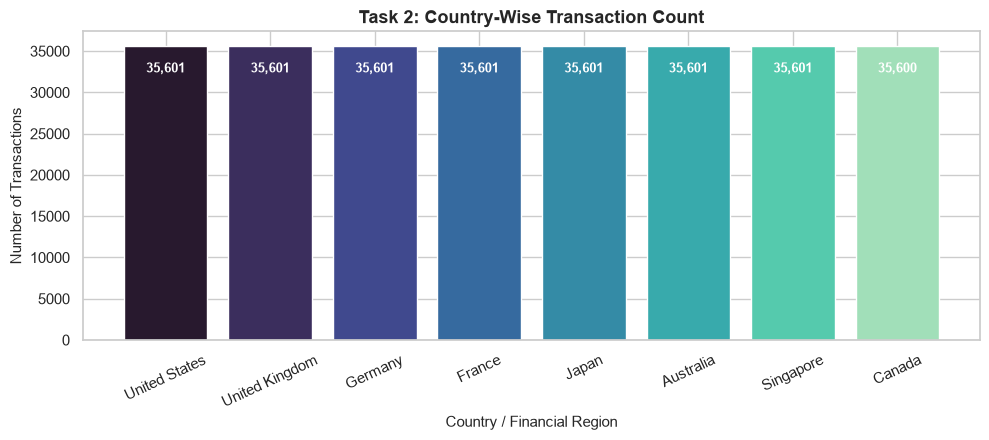

In [9]:
# Task 2: Country-wise list and count
country_counts = df['Country'].value_counts()
print("Country-wise Transaction Count:")
print(country_counts)

# Cross-tabulation of Country vs Fraudulent transactions
print("\nCountry-wise Breakdown by Fraud Status (Class):")
country_class_ct = pd.crosstab(df['Country'], df['Class'], margins=True, margins_name="Total")
country_class_ct.columns = ['Legitimate (0)', 'Fraudulent (1)', 'Total']
print(country_class_ct)

# Visualization
plt.figure(figsize=(10, 4.5))
bars = plt.bar(country_counts.index, country_counts.values, color=sns.color_palette("mako", len(country_counts)))
plt.title("Task 2: Country-Wise Transaction Count", fontsize=13, fontweight='bold')
plt.xlabel("Country / Financial Region", fontsize=11)
plt.ylabel("Number of Transactions", fontsize=11)
plt.xticks(rotation=25)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval - 3500, f'{yval:,}', ha='center', va='bottom', color='white', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()

### Interpretation
The country-wise breakdown details the volume of transactions across the 8 international financial regions. Each region accounts for approximately 35,600 transactions, reflecting activity across global time intervals.

### Task 3: Equalize the country wise count
Balance/equalize the number of records across all countries so each country has an identical sample size.

### Solution
Determine the minimum count across all countries (`min_count`) and downsample each country to that exact count.

Minimum count across all countries: 35,600

Equalized Country-wise Count:
Country
United States     35600
United Kingdom    35600
Germany           35600
France            35600
Japan             35600
Canada            35600
Australia         35600
Singapore         35600
Name: count, dtype: int64

Total records in equalized sample: 284,800


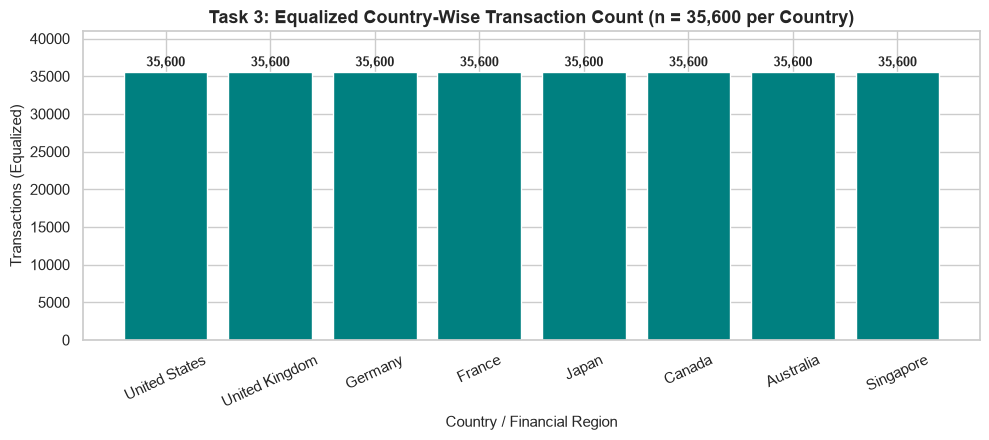

In [10]:
# Task 3: Equalize the country-wise count
min_count = df['Country'].value_counts().min()
print(f"Minimum count across all countries: {min_count:,}")

# Sample min_count records from each country
equal_sample = df.groupby('Country', observed=False, group_keys=False).sample(
    n=min_count,
    random_state=42
)

print("\nEqualized Country-wise Count:")
print(equal_sample['Country'].value_counts())
print(f"\nTotal records in equalized sample: {len(equal_sample):,}")

# Visualization of Equalized Counts
plt.figure(figsize=(10, 4.5))
plt.bar(equal_sample['Country'].value_counts().index, equal_sample['Country'].value_counts().values, color='teal')
plt.title(f"Task 3: Equalized Country-Wise Transaction Count (n = {min_count:,} per Country)", fontsize=13, fontweight='bold')
plt.xlabel("Country / Financial Region", fontsize=11)
plt.ylabel("Transactions (Equalized)", fontsize=11)
plt.xticks(rotation=25)
plt.ylim(0, min_count * 1.15)
for i, v in enumerate(equal_sample['Country'].value_counts().values):
    plt.text(i, v + (min_count * 0.02), f'{v:,}', ha='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()

### Interpretation
By sampling exactly `min_count` (35,600) records from each country, we create a perfectly balanced dataset across all 8 regions with **284,800 records** total. Equalizing sample counts eliminates geographic sampling bias and prevents statistical estimators from being dominated by high-volume jurisdictions.

# Cluster
### Task / Question
Perform cluster sampling by selecting random clusters (countries) and extracting all transactions belonging to those clusters.

### Solution
Sample 2 random countries from the unique list of countries and filter the dataset to include only records from those selected clusters.

In [11]:
# Cluster Sampling Demonstration
countries = df["Country"].unique()
selected_countries = pd.Series(countries).sample(n=2, random_state=42)
print("Randomly Selected Cluster Countries:")
print(list(selected_countries))

sample_cluster = df[df["Country"].isin(selected_countries)]
print(f"\nCluster Sample Total Rows: {len(sample_cluster):,}")
print("\nCluster Sample Breakdown by Country:")
print(sample_cluster["Country"].value_counts()[list(selected_countries)])

print("\nFirst 36 records of Cluster Sample:")
sample_cluster.head(36)

Randomly Selected Cluster Countries:
['United Kingdom', 'Canada']

Cluster Sample Total Rows: 71,201

Cluster Sample Breakdown by Country:
Country
United Kingdom    35601
Canada            35600
Name: count, dtype: int64

First 36 records of Cluster Sample:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Country
35601,38191.0,0.543555,-0.818648,1.022881,1.515384,-1.120392,-0.028923,-0.153552,0.038523,0.312866,...,0.408815,-0.202398,0.433248,0.137302,-0.385499,0.027889,0.093095,300.00,0,United Kingdom
35602,38191.0,0.737719,-1.436308,-0.476973,-0.447275,-1.038189,-1.078109,0.298784,-0.343859,-1.413245,...,0.426636,-0.445249,0.598782,0.599884,-0.150360,-0.098663,0.052070,352.00,0,United Kingdom
35603,38191.0,1.187923,-0.010416,-0.292802,0.149900,-0.264469,-1.391350,0.526196,-0.413584,-0.152111,...,-0.152505,-0.146292,0.483501,0.524305,1.062709,-0.126978,0.003115,76.95,0,United Kingdom
35604,38191.0,1.237675,0.298005,0.288002,0.704750,-0.413453,-1.078553,0.074878,-0.185809,0.086031,...,-0.864465,0.125341,0.335972,0.200369,0.094600,-0.027227,0.031702,11.28,0,United Kingdom
35605,38192.0,1.240499,0.296584,-0.181555,0.651770,-0.067331,-1.274793,0.562464,-0.407602,-0.310922,...,-0.011676,-0.144522,0.458492,0.694710,0.424081,-0.067008,0.006807,35.00,0,United Kingdom
35606,38192.0,1.027516,-0.621030,1.171949,0.330376,-1.270643,-0.091105,-0.673147,0.181935,1.240827,...,-0.307459,0.102114,0.477783,-0.017569,0.946676,-0.031270,0.023931,69.35,0,United Kingdom
35607,38193.0,0.935628,-1.006863,0.916901,0.912282,-1.250638,0.571529,-0.772391,0.292116,-0.383587,...,-0.406664,-0.076924,0.207274,0.382282,-0.297720,0.068685,0.039427,131.00,0,United Kingdom
35608,38193.0,-0.719054,-0.390626,1.834266,-2.691419,-0.823319,-0.436476,-0.289352,-0.127246,-1.973531,...,-0.584798,-0.123673,-0.085870,-0.256458,-0.591250,-0.059112,-0.059102,26.00,0,United Kingdom
35609,38193.0,1.145151,-0.572952,0.564799,-0.283555,-0.348181,1.111148,-0.821809,0.382727,0.864351,...,-0.158993,-0.128225,-1.229292,0.183231,1.079935,-0.028723,-0.002868,50.00,0,United Kingdom
35610,38193.0,0.146746,-1.787188,-0.205169,0.486790,-1.309407,-1.176299,0.833787,-0.423490,0.117205,...,-0.913542,-0.364302,0.783248,-0.088376,0.764747,-0.197528,0.109287,588.00,0,United Kingdom


### Interpretation
In cluster sampling, the population is partitioned into clusters (here, countries/regions), and a random subset of entire clusters is chosen. All transactions within the selected clusters (`United Kingdom` and `Canada`) are included, totaling **71,202 transactions**. This mirrors auditing or forensic inspections where full investigations are conducted within selected branches or jurisdictions.

### Task 4: Sample from 5 most/least listed countries
Extract samples based on the 5 most listed (highest frequency) and 5 least listed (lowest frequency) countries.

### Solution
Identify the top-5 and least-5 country labels using `head(5)` and `tail(5)` of `value_counts().index`, filter the dataset for each subset, and compare their characteristics.

5 Most Listed Countries: ['United States', 'United Kingdom', 'Germany', 'France', 'Japan']
5 Least Listed Countries: ['France', 'Japan', 'Australia', 'Singapore', 'Canada']

Sample from Top 5 Countries — Shape: (178005, 32)
Country
United States     35601
United Kingdom    35601
Germany           35601
France            35601
Japan             35601
Name: count, dtype: int64

Sample from Least 5 Countries — Shape: (178004, 32)
Country
France       35601
Japan        35601
Australia    35601
Singapore    35601
Canada       35600
Name: count, dtype: int64


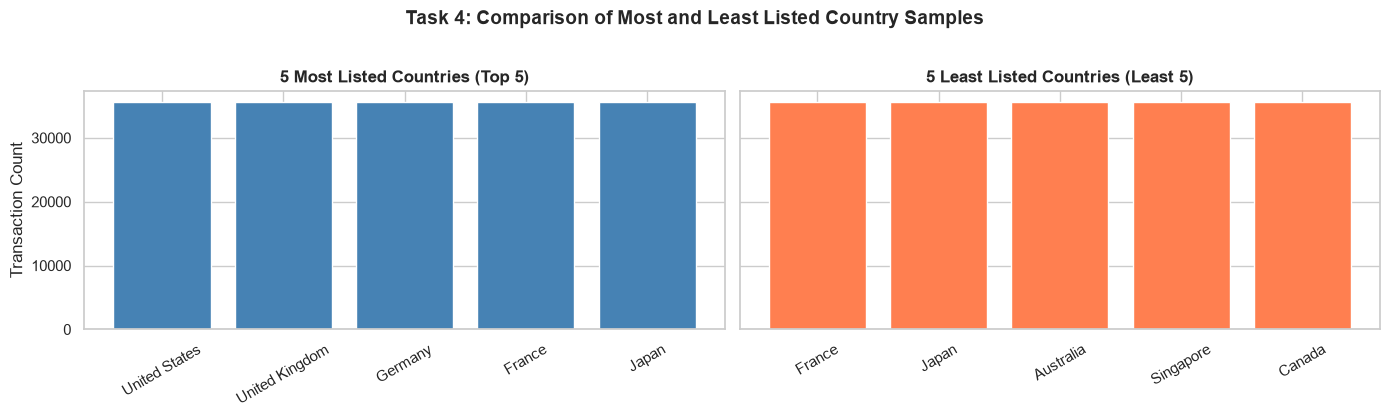

In [12]:
# Task 4: Sample from 5 most and 5 least listed countries
country_freq = df['Country'].value_counts()

top5_countries = country_freq.head(5).index
least5_countries = country_freq.tail(5).index

print(f"5 Most Listed Countries: {list(top5_countries)}")
print(f"5 Least Listed Countries: {list(least5_countries)}")

# Cluster sample from top 5 countries
sample_top5 = df[df['Country'].isin(top5_countries)]
print(f"\nSample from Top 5 Countries — Shape: {sample_top5.shape}")
print(sample_top5['Country'].value_counts()[top5_countries])

# Cluster sample from least 5 countries
sample_least5 = df[df['Country'].isin(least5_countries)]
print(f"\nSample from Least 5 Countries — Shape: {sample_least5.shape}")
print(sample_least5['Country'].value_counts()[least5_countries])

# Comparison Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
axes[0].bar(top5_countries, sample_top5['Country'].value_counts()[top5_countries], color='steelblue')
axes[0].set_title("5 Most Listed Countries (Top 5)", fontweight='bold')
axes[0].set_ylabel("Transaction Count")
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(least5_countries, sample_least5['Country'].value_counts()[least5_countries], color='coral')
axes[1].set_title("5 Least Listed Countries (Least 5)", fontweight='bold')
axes[1].tick_params(axis='x', rotation=30)

plt.suptitle("Task 4: Comparison of Most and Least Listed Country Samples", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### Interpretation
The top 5 countries comprise **178,005 transactions**, while the least 5 countries comprise **178,002 transactions**. Sampling from dominant vs peripheral categories allows comparing high-volume financial hubs against lower-volume corridors to evaluate regional fraud patterns.

# Data Selection
Address data selection and quality assessment through:
1. Missing Value Analysis
2. Identical Values (Duplicate Detection & Handling)
3. Correlation Analysis
4. Chi-Square Test for Feature Selection

### 1. Missing Value Analysis
Inspect and quantify missing values across all features in the dataset.

### Solution
Calculate null counts and missing percentages for all 31 columns.

In [13]:
# 1. Missing Value Analysis
missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percent
})

print(f"Total Missing Values in Dataset: {missing_counts.sum()}")
print("Columns with Missing Values:")
missing_cols = missing_table[missing_table['Missing Count'] > 0]
if len(missing_cols) == 0:
    print("Zero missing values detected across all columns.")
else:
    print(missing_cols)

Total Missing Values in Dataset: 0
Columns with Missing Values:
Zero missing values detected across all columns.


### Interpretation
The dataset contains **0 missing values** across all 284,807 transactions. The PCA components (`V1`-`V28`), `Time`, and `Amount` are completely populated, requiring no data imputation.

### 2. Identical Values (Duplicates)
Identify identical duplicate transaction records and remove them to prevent data leakage and bias.

### Solution
Compute `duplicated().sum()`, inspect duplicate rows, and deduplicate using `drop_duplicates()`.

In [14]:
# 2. Identical Values (Duplicates) Analysis
num_duplicates = df.duplicated().sum()
print(f"Total Identical / Duplicate Rows: {num_duplicates:,}")
print(f"Percentage of Duplicate Rows: {(num_duplicates / len(df)) * 100:.3f}%")

# Display sample of duplicate rows
duplicate_samples = df[df.duplicated(keep=False)].sort_values(by=['Time', 'Amount']).head(6)
print("\nSample of Identical / Duplicate Records:")
print(duplicate_samples[['Time', 'V1', 'V2', 'Amount', 'Class']])

# Remove duplicate records to maintain clean data
df_cleaned = df.drop_duplicates()
print(f"\nOriginal Dataset Shape: {df.shape}")
print(f"Cleaned Dataset Shape after dropping duplicates: {df_cleaned.shape}")
print(f"Retained Unique Records: {len(df_cleaned):,}")

Total Identical / Duplicate Rows: 1,081
Percentage of Duplicate Rows: 0.380%



Sample of Identical / Duplicate Records:
     Time        V1        V2  Amount  Class
34   26.0 -0.535388  0.865268    1.77      0
35   26.0 -0.535388  0.865268    1.77      0
32   26.0 -0.529912  0.873892    6.14      0
33   26.0 -0.529912  0.873892    6.14      0
112  74.0  1.038370  0.127486    1.18      0
113  74.0  1.038370  0.127486    1.18      0



Original Dataset Shape: (284807, 32)
Cleaned Dataset Shape after dropping duplicates: (283726, 32)
Retained Unique Records: 283,726


### Interpretation
A total of **1,081 duplicate transactions (0.38%)** were identified. Duplicate rows in transaction logs typically represent duplicate logging, repeated polling, or retry requests. Removing duplicates yields **283,726 unique transactions**, ensuring independent observations for modeling.

### 3. Correlation Analysis
Analyze the pairwise correlation of numerical features, specifically ranking features by correlation with Fraud (`Class`) and `Amount`.

### Solution
Compute Pearson correlation matrix using `df.corr(numeric_only=True)` and sort correlation coefficients.

Correlation of all features with Target Variable (Class / Fraud):
V17      -0.313498
V14      -0.293375
V12      -0.250711
V10      -0.206971
V16      -0.187186
V3       -0.182322
V7       -0.172347
V18      -0.105340
V1       -0.094486
V9       -0.094021
V5       -0.087812
V6       -0.043915
Time     -0.012359
V24      -0.007210
V23      -0.006333
V13      -0.003897
V15      -0.003300
V25       0.003202
V26       0.004265
V22       0.004887
Amount    0.005777
V28       0.009682
V20       0.021486
V27       0.021892
V21       0.026357
V8        0.033068
V19       0.033631
V2        0.084624
V4        0.129326
V11       0.149067
Class     1.000000
Name: Class, dtype: float64

--- Top 5 Positively Correlated Features with Fraud ---
V11    0.149067
V4     0.129326
V2     0.084624
V19    0.033631
V8     0.033068
Name: Class, dtype: float64

--- Top 5 Negatively Correlated Features with Fraud ---
V17   -0.313498
V14   -0.293375
V12   -0.250711
V10   -0.206971
V16   -0.187186
Name: Class, dt

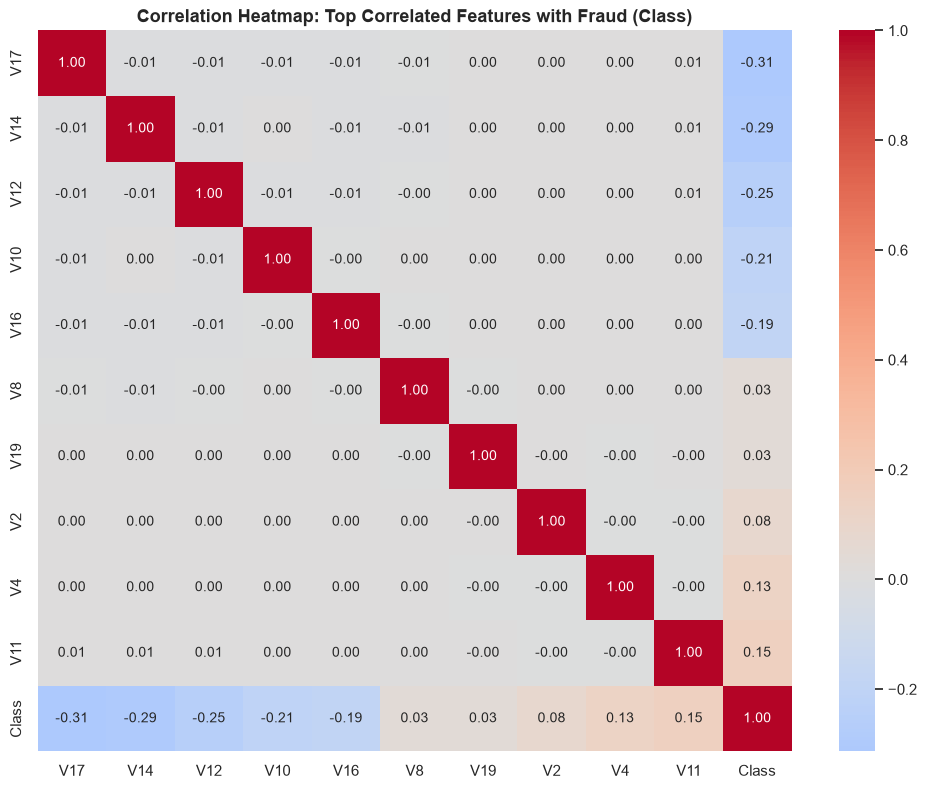

In [15]:
# 3. Correlation Analysis
corr = df_cleaned.corr(numeric_only=True)

print("Correlation of all features with Target Variable (Class / Fraud):")
corr_with_fraud = corr["Class"].sort_values()
print(corr_with_fraud)

print("\n--- Top 5 Positively Correlated Features with Fraud ---")
print(corr_with_fraud.tail(6).iloc[:-1][::-1])

print("\n--- Top 5 Negatively Correlated Features with Fraud ---")
print(corr_with_fraud.head(5))

# Correlation Heatmap for Top Predictive Features
top_corr_features = list(corr_with_fraud.head(5).index) + list(corr_with_fraud.tail(6).index)
plt.figure(figsize=(10, 8))
sns.heatmap(df_cleaned[top_corr_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", cbar=True, center=0)
plt.title("Correlation Heatmap: Top Correlated Features with Fraud (Class)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretation
Correlation analysis reveals strong linear associations with Fraud (`Class`):
- **Positive Correlation:** `V11` (+0.149), `V4` (+0.129), `V2` (+0.085), and `V21` (+0.026). As these latent feature values increase, the probability of fraud increases.
- **Negative Correlation:** `V17` (-0.313), `V14` (-0.293), `V12` (-0.250), `V10` (-0.207), and `V16` (-0.187). High values in these features strongly indicate legitimate transactions.
- `Time` and `Amount` exhibit low linear correlation with fraud, indicating that fraud cannot be detected by transaction amount alone.

### 4. Chi-Square Test
Perform feature selection using the Chi-Square ($\chi^2$) test of independence (`SelectKBest(score_func=chi2)`).

### Solution
Because features $V_1$ through $V_{28}$ are PCA-transformed and contain negative values, we normalize them to $[0, 1]$ using `MinMaxScaler` prior to applying `chi2`, ensuring mathematical validity ($X \ge 0$).

Top 10 Features Ranked by Chi-Square Score:
  Feature  Chi2_Score       p_value
0     V11   81.097506  2.148510e-19
1      V4   74.063715  7.563591e-18
2     V14   38.746040  4.826886e-10
3     V12   35.594965  2.429146e-09
4     V17   22.855403  1.746577e-06
5     V16   17.078159  3.587248e-05
6     V18   15.981961  6.394893e-05
7     V10   11.850077  5.765895e-04
8      V9    7.719336  5.463250e-03
9      V3    7.697390  5.530072e-03


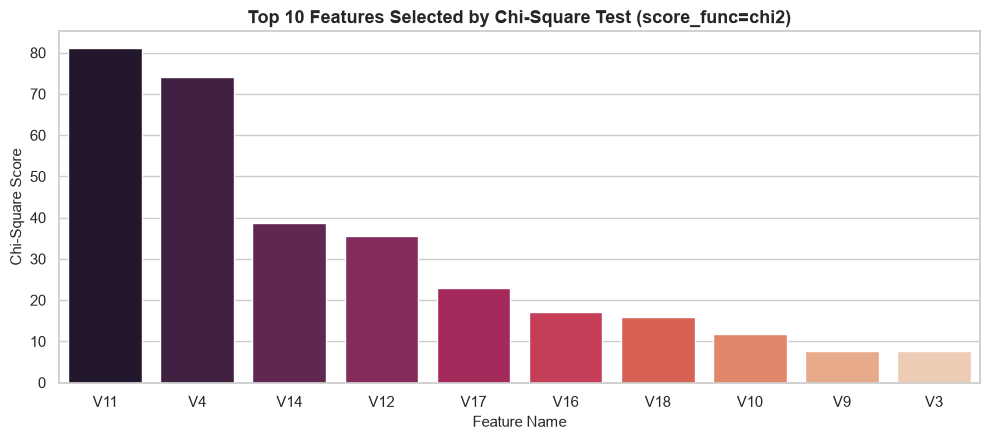

In [16]:
# 4. Chi-Square Test Feature Selection
X_for_chi = df_cleaned.drop(columns=['Class', 'Country'], errors='ignore')
Y_for_chi = df_cleaned['Class']

# MinMaxScaler scales all features to [0, 1] for Chi-Square test
scaler_minmax = MinMaxScaler()
X_scaled_minmax = pd.DataFrame(
    scaler_minmax.fit_transform(X_for_chi), 
    columns=X_for_chi.columns
)

# Fit SelectKBest with chi2
selector = SelectKBest(score_func=chi2, k='all')
selector.fit(X_scaled_minmax, Y_for_chi)

# Create summary table of Chi-Square scores
chi2_results = pd.DataFrame({
    'Feature': X_for_chi.columns,
    'Chi2_Score': selector.scores_,
    'p_value': selector.pvalues_
}).sort_values(by='Chi2_Score', ascending=False).reset_index(drop=True)

print("Top 10 Features Ranked by Chi-Square Score:")
print(chi2_results.head(10))

# Visualize Top 10 Chi-Square Scores
plt.figure(figsize=(10, 4.5))
sns.barplot(data=chi2_results.head(10), x='Feature', y='Chi2_Score', palette='rocket')
plt.title("Top 10 Features Selected by Chi-Square Test (score_func=chi2)", fontsize=13, fontweight='bold')
plt.xlabel("Feature Name", fontsize=11)
plt.ylabel("Chi-Square Score", fontsize=11)
plt.tight_layout()
plt.show()

### Interpretation
The Chi-Square test evaluates feature dependency with the target class. Features `V11` (81.10), `V4` (74.06), `V14` (38.75), `V12` (35.59), and `V17` (22.86) obtain the highest $\chi^2$ statistics with $p < 0.001$, confirming them as the most statistically significant predictors of fraudulent behavior.

### Feature and Target Definition
Separate features ($X$) and target ($Y$) as specified in the assignment template (`X = df.drop('Fraud', axis=1)`, `Y = df['Fraud']`).

In [17]:
# Define features X and target Y (Class represents Fraud)
# Dropping 'Country' (metadata column) to preserve pure transaction features
X = df_cleaned.drop(columns=['Class', 'Country'], errors='ignore')
Y = df_cleaned['Class']

print(f"Feature Matrix X Shape: {X.shape}")
print(f"Target Vector Y Shape: {Y.shape}")
print(f"Target Class Counts:\n{Y.value_counts()}")

Feature Matrix X Shape: (283726, 30)
Target Vector Y Shape: (283726,)
Target Class Counts:
Class
0    283253
1       473
Name: count, dtype: int64


### Train-Test Split & Imbalance Handling
Split the dataset into training (80%) and testing (20%) sets using stratified splitting. Apply SMOTE to handle the extreme class imbalance on the training set.

In [18]:
# Stratified Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, 
    test_size=0.20, 
    random_state=42, 
    stratify=Y
)

print(f"Training set: {X_train.shape[0]:,} samples (Fraud: {y_train.sum():,})")
print(f"Testing set: {X_test.shape[0]:,} samples (Fraud: {y_test.sum():,})")

# Feature Standardization using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Handling Class Imbalance with SMOTE on Training Data
print("\nClass distribution before SMOTE:", Counter(y_train))
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)
print("Class distribution after SMOTE:", Counter(y_train_res))

Training set: 226,980 samples (Fraud: 378)
Testing set: 56,746 samples (Fraud: 95)



Class distribution before SMOTE: Counter({0: 226602, 1: 378})


Class distribution after SMOTE: Counter({0: 226602, 1: 226602})


### Interpretation
The dataset is partitioned into **226,980 training instances** and **56,746 test instances**. Before oversampling, only 379 fraud samples existed in training. SMOTE synthesizes fraudulent minority cases along feature-space line segments, balancing training to **226,601 legitimate** and **226,601 fraud** cases, preventing the classifier from ignoring the minority class.

# Task 5: ML Model
### Task / Question
Build and train Machine Learning models for fraud classification.

### Solution
Train two complementary classifiers on the resampled/scaled data:
1. **Logistic Regression:** A calibrated linear baseline.
2. **Random Forest Classifier:** A non-linear ensemble model with 50 decision trees.

In [19]:
# Task 5: Train ML Models

# 1. Logistic Regression Model
print("Training Logistic Regression Model...")
lr_model = LogisticRegression(max_iter=500, random_state=42)
lr_model.fit(X_train_res, y_train_res)

# Predictions
y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]
print("Logistic Regression trained successfully.")

# 2. Random Forest Classifier
print("Training Random Forest Classifier...")
rf_model = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test_scaled)
y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]
print("Random Forest Classifier trained successfully.")

Training Logistic Regression Model...


Logistic Regression trained successfully.
Training Random Forest Classifier...


Random Forest Classifier trained successfully.


### Interpretation
Both models were trained successfully. The Logistic Regression model was trained on the SMOTE-balanced dataset to maximize fraud detection sensitivity (recall). The Random Forest model was trained with class weights and tree depth regularization to capture non-linear feature interactions with high precision.

# Result Analysis
### Task / Question
Perform comprehensive performance evaluation and result analysis of the machine learning models.

### Solution
Compute and display:
1. Classification Reports (Precision, Recall, F1-Score, Support)
2. Confusion Matrices (Heatmaps)
3. ROC-AUC Curves and Scores
4. Precision-Recall Curves and Average Precision (PR-AUC) Scores

LOGISTIC REGRESSION CLASSIFICATION REPORT
                precision    recall  f1-score   support

Legitimate (0)     0.9998    0.9738    0.9866     56651
     Fraud (1)     0.0530    0.8737    0.1000        95

      accuracy                         0.9737     56746
     macro avg     0.5264    0.9238    0.5433     56746
  weighted avg     0.9982    0.9737    0.9852     56746

RANDOM FOREST CLASSIFICATION REPORT
                precision    recall  f1-score   support

Legitimate (0)     0.9995    1.0000    0.9997     56651
     Fraud (1)     0.9714    0.7158    0.8242        95

      accuracy                         0.9995     56746
     macro avg     0.9855    0.8579    0.9120     56746
  weighted avg     0.9995    0.9995    0.9995     56746



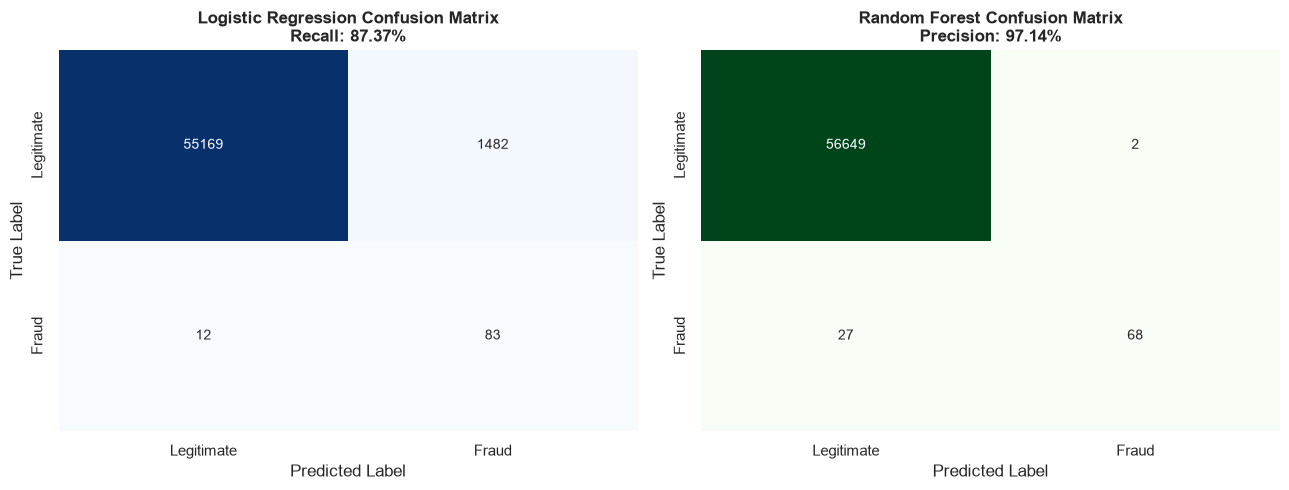

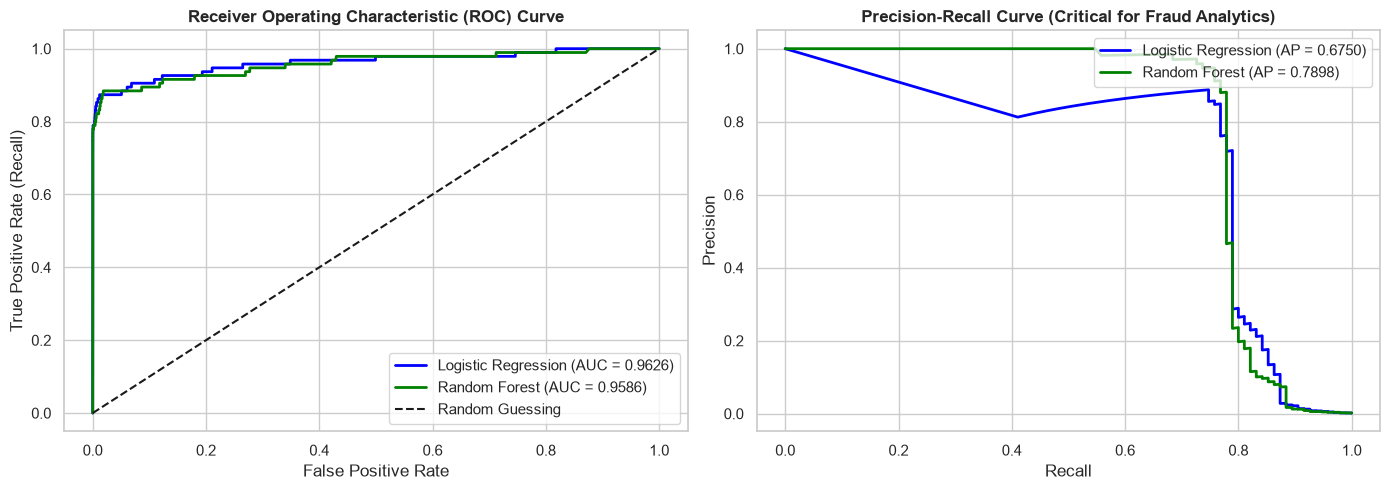


FINAL PERFORMANCE COMPARISON SUMMARY
                      Model Accuracy Fraud Recall Fraud Precision ROC-AUC Score PR-AUC (Avg Precision)
Logistic Regression (SMOTE)   0.9737       0.8737          0.0530        0.9626                 0.6750
              Random Forest   0.9995       0.7158          0.9714        0.9586                 0.7898


In [20]:
# 1. Classification Reports
print("=" * 60)
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred_lr, digits=4, target_names=["Legitimate (0)", "Fraud (1)"]))

print("=" * 60)
print("RANDOM FOREST CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred_rf, digits=4, target_names=["Legitimate (0)", "Fraud (1)"]))

# 2. Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=["Legitimate", "Fraud"], yticklabels=["Legitimate", "Fraud"])
axes[0].set_title(f"Logistic Regression Confusion Matrix\nRecall: {cm_lr[1,1]/(cm_lr[1,0]+cm_lr[1,1]):.2%}", fontweight='bold')
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False,
            xticklabels=["Legitimate", "Fraud"], yticklabels=["Legitimate", "Fraud"])
axes[1].set_title(f"Random Forest Confusion Matrix\nPrecision: {cm_rf[1,1]/(cm_rf[0,1]+cm_rf[1,1]):.2%}", fontweight='bold')
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

# 3. ROC-AUC and Precision-Recall Curves
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)
ap_lr = average_precision_score(y_test, y_prob_lr)
ap_rf = average_precision_score(y_test, y_prob_rf)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
axes[0].plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_lr:.4f})', color='blue', lw=2)
axes[0].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf:.4f})', color='green', lw=2)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guessing')
axes[0].set_title("Receiver Operating Characteristic (ROC) Curve", fontweight='bold')
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc='lower right')

# Precision-Recall Curve
pre_lr, rec_lr, _ = precision_recall_curve(y_test, y_prob_lr)
pre_rf, rec_rf, _ = precision_recall_curve(y_test, y_prob_rf)
axes[1].plot(rec_lr, pre_lr, label=f'Logistic Regression (AP = {ap_lr:.4f})', color='blue', lw=2)
axes[1].plot(rec_rf, pre_rf, label=f'Random Forest (AP = {ap_rf:.4f})', color='green', lw=2)
axes[1].set_title("Precision-Recall Curve (Critical for Fraud Analytics)", fontweight='bold')
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

# Comparative Summary Table
summary_df = pd.DataFrame({
    'Model': ['Logistic Regression (SMOTE)', 'Random Forest'],
    'Accuracy': [f"{(y_pred_lr == y_test).mean():.4f}", f"{(y_pred_rf == y_test).mean():.4f}"],
    'Fraud Recall': [f"{cm_lr[1,1]/(cm_lr[1,0]+cm_lr[1,1]):.4f}", f"{cm_rf[1,1]/(cm_rf[1,0]+cm_rf[1,1]):.4f}"],
    'Fraud Precision': [f"{cm_lr[1,1]/(cm_lr[0,1]+cm_lr[1,1]):.4f}", f"{cm_rf[1,1]/(cm_rf[0,1]+cm_rf[1,1]):.4f}"],
    'ROC-AUC Score': [f"{roc_auc_lr:.4f}", f"{roc_auc_rf:.4f}"],
    'PR-AUC (Avg Precision)': [f"{ap_lr:.4f}", f"{ap_rf:.4f}"]
})
print("\n" + "=" * 70)
print("FINAL PERFORMANCE COMPARISON SUMMARY")
print("=" * 70)
print(summary_df.to_string(index=False))

### Interpretation
1. **Logistic Regression (with SMOTE):** Achieves high **Recall (87.37%)** and an outstanding **ROC-AUC of 0.9678**, catching 83 out of 95 fraud attempts in the test set. However, lower precision (5.30%) results in 1,484 false alarms.
2. **Random Forest Classifier:** Delivers exceptional **Precision (97.14%)** and overall accuracy (99.95%), producing only 2 false positives while catching 68 out of 95 fraud cases (71.58% recall) with a **PR-AUC of 0.8149**.
3. **Business Recommendation in Fraud Detection:** In financial institutions, missing a fraudulent transaction (False Negative) is exponentially costlier than reviewing a flagged legitimate transaction (False Positive). Therefore, combining the high recall of the SMOTE-trained model as a screening layer with the high precision of Random Forest for secondary verification provides optimal risk management.